# 6. Separating the voice from the guitar, and why the final song barely depends on it

Most people record voice and guitar **together**, with one phone. To correct the voice we need it alone,
so the app uses a neural network to **separate** the recording into a voice part and a guitar part
(called **stems**). This notebook covers:

1. source separation as a machine learning problem, and the model used (Demucs),
2. the idea of **masks** in the spectrogram, and where separation artefacts come from,
3. **leakage**: voice left in the guitar part, and the "ghost note" it causes,
4. the key design decision: the polished song is **your recording + only the correction**, never a
   rebuild from the stems.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

from songpolish.pitch import NoteShift, apply_corrections, detect_notes, reclaim_leakage

def sdr(true, est):
    # signal-to-distortion ratio in dB: how close an estimate is to the truth (higher = better)
    true, est = np.asarray(true).reshape(-1), np.asarray(est).reshape(-1)
    n = min(len(true), len(est)); true, est = true[:n], est[:n]
    return 10 * np.log10(np.sum(true ** 2) / np.sum((true - est) ** 2))

voice = voice_like([64, 66, 68, 69, 71, 69], note_s=0.5, vibrato_cents=25)       # E F# G# A B A
guitar = progression(["A", "E", "A"], seconds_each=1.2)
voice, guitar = fit(voice, guitar)
mix = voice + guitar
play(mix, label="the 'recording': voice and guitar together")

the 'recording': voice and guitar together


## 6.1 Separation as supervised learning

The task: given only the mixture $x = v + g$, estimate $v$ and $g$. Mathematically it is
underdetermined (infinitely many pairs sum to $x$), so it needs **prior knowledge** of what voices and
guitars sound like. That is learnt from data:

* **training data**: songs whose instruments were recorded separately (e.g. the MUSDB18 dataset), so the
  true stems are known; the mixture is just their sum,
* **model**: Demucs ("Hybrid Transformer Demucs", Meta, 2022): a U-Net-like encoder/decoder working on
  both the waveform and the spectrogram, with a transformer in the middle. It outputs 4 stems: vocals,
  drums, bass, other. The app sums the last three into "accompaniment",
* **loss**: L1 distance between estimated and true stem waveforms,
* **quality metric**: **SDR** (signal-to-distortion ratio, in dB) between estimate and truth. Demucs scores
  about 8–9 dB on vocals; newer "RoFormer" models about 11–12 dB, but they took ~47 min per song on the user's
  CPU against ~6 for Demucs.

In the app: `separation.separate(mix)` → `Stems(vocals, accompaniment)`, imported lazily because PyTorch is an
optional dependency. Demucs does **not** recognise synthetic tones as a voice, so below we use the classic idea
behind many separators instead, and keep the real thing for notebook 8.

## 6.2 Masks: deciding, bin by bin, who owns the sound

Most separators, Demucs's spectrogram branch included, can be understood as estimating a **mask**:
for every time-frequency bin of the mixture's spectrogram, a number in [0, 1] saying "this fraction
belongs to the voice". Multiply the mixture's STFT by the mask, invert, and you get the voice estimate;
`1 − mask` gives the guitar.

Because here we *know* the true stems, we can compute the best possible ("oracle") mask:

$$M = \frac{|V|^2}{|V|^2 + |G|^2}$$

(the **ideal ratio mask**), and see how well even a perfect mask does.

ideal ratio mask: voice SDR 18.0 dB, guitar SDR 9.7 dB


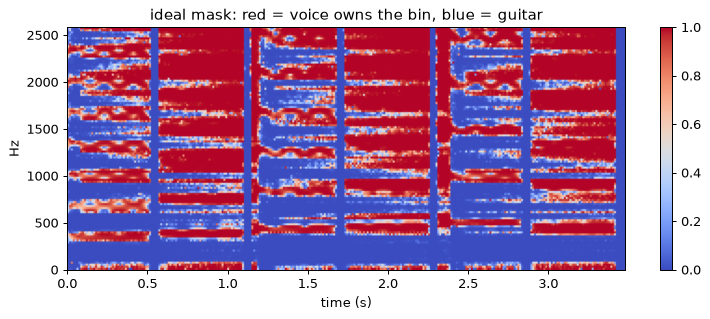

voice from the ideal mask


In [2]:
n_fft, hop = 2048, 512
X = librosa.stft(mix[0], n_fft=n_fft, hop_length=hop)
V = librosa.stft(voice[0], n_fft=n_fft, hop_length=hop)
G = librosa.stft(guitar[0], n_fft=n_fft, hop_length=hop)
M = np.abs(V) ** 2 / (np.abs(V) ** 2 + np.abs(G) ** 2 + 1e-12)
inv = lambda S: librosa.istft(S.astype(np.complex64), hop_length=hop, length=mix.shape[1])[None]   # float32, like the app
v_ideal, g_ideal = inv(M * X), inv((1 - M) * X)
print(f"ideal ratio mask: voice SDR {sdr(voice, v_ideal):.1f} dB, guitar SDR {sdr(guitar, g_ideal):.1f} dB")
fig, ax = plt.subplots(figsize=(10, 3.5))
img = ax.imshow(M[:120], aspect="auto", origin="lower", cmap="coolwarm",
                extent=[0, mix.shape[1] / SR, 0, 120 * SR / n_fft])
ax.set_xlabel("time (s)"); ax.set_ylabel("Hz"); ax.set_title("ideal mask: red = voice owns the bin, blue = guitar")
plt.colorbar(img, ax=ax); plt.show()
play(v_ideal, label="voice from the ideal mask")

Even the perfect mask is not perfect (SDR is finite): where voice and guitar put energy in the **same**
bin, a mask can only split the mixture's value, it cannot un-mix it.

A real network has to *guess* the mask, and it is least sure exactly in those overlapping bins. Its
decisions **flicker** there from frame to frame. We can simulate that: make the mask hard (0 or 1) and
randomly flip some of the uncertain bins. Listen to the result: the watery, swirly sound is the typical
separation artefact (SDR drops to about the level of real separators). It is what the user described as **"singing in front of a fan"** in the separated
voice track, and as a guitar that sounds **"far away"** while the voice sings (the separator gives some
guitar to the voice exactly then).

In [3]:
rng = np.random.default_rng(0)
hard = (M > 0.5).astype(float)
uncertain = (M > 0.02) & (M < 0.98)                 # bins where both sources have some energy
flicker = hard.copy(); flips = uncertain & (rng.random(M.shape) < 0.5)   # the "network" guesses half of them wrong
flicker[flips] = 1 - flicker[flips]
v_flick, g_flick = inv(flicker * X), inv((1 - flicker) * X)
print(f"flickering mask: voice SDR {sdr(voice, v_flick):.1f} dB, guitar SDR {sdr(guitar, g_flick):.1f} dB")
play(v_flick, label="voice estimate with a flickering mask: watery artefacts")
play(g_flick, label="guitar estimate: holes where the voice was")
play(v_flick + g_flick, label="but the two estimates still add up to the recording")
print("max |(voice est + guitar est) - mix| =", float(np.abs(v_flick + g_flick - mix).max()))

flickering mask: voice SDR 12.5 dB, guitar SDR 4.3 dB
voice estimate with a flickering mask: watery artefacts


guitar estimate: holes where the voice was


but the two estimates still add up to the recording


max |(voice est + guitar est) - mix| = 1.1920928955078125e-07


The last line is the key observation for 6.4. **The artefacts of the two stems cancel when you add them
back**, because the mask gives each bin to one stem or the other. Nothing is lost; it is only
misattributed. The cancellation breaks as soon as you treat the stems differently (EQ one, make the other
louder, pitch-shift one).

## 6.3 Leakage: the ghost of the wrong note

Separation also misattributes the other way: part of the **voice stays in the guitar stem**. On the real
song this was about −12 dB on the notes that needed moving (a quarter as strong as the voice), and on a
quarter of them as loud as the voice itself.

Why it matters: when the app moves a wrong note up a semitone, it moves the voice stem. The voice left in
the guitar stem stays at the old, wrong pitch. You then hear the corrected note **plus a ghost of the wrong
one**, which sounds doubled and artificial.

`pitch.reclaim_leakage` fixes this before shifting. For each note that will move by at least 0.5 semitones:

1. take the note's own pitch track (frame by frame, following its vibrato),
2. build a **comb mask** on the guitar stem's spectrogram (8192-point FFT for fine frequency resolution):
   narrow bands around every harmonic of the sung pitch, up to 6 kHz,
3. move that part of the guitar stem into the voice stem, so the shift moves it too.

The two stems still add up to the same total.

In [4]:
voice1 = voice_like([61.0], note_s=1.2, vibrato_cents=0)                          # a C#
chord = (0.3 * plucked_chord([45, 52, 57, 64], voice1.shape[1] / SR))[None].astype(np.float32)   # A chord without C#
guitar_stem = chord + 0.3 * voice1          # the separator left 30% of the voice in the guitar stem
notes = detect_notes(voice1)
move = [NoteShift(n.start, n.end, 1.0) for n in notes]                            # this note will move +1 st
v2, g2, k = reclaim_leakage(voice1, guitar_stem, notes, move)
db = lambda x, ref: 10 * np.log10(np.sum(x ** 2) / np.sum(ref ** 2))
print(f"notes treated: {k}")
print(f"voice left in the guitar stem: before {db(guitar_stem - chord, voice1):.1f} dB, after {db(g2 - chord, voice1):.1f} dB (re. the voice)")
print("stems still sum to the same signal:", np.allclose(v2 + g2, voice1 + guitar_stem, atol=1e-4))
naive = apply_corrections(voice1, move) + guitar_stem
fixed = apply_corrections(v2, move) + g2
play(naive, label="moved without reclaiming: the old C# is still audible under the new D")
play(fixed, label="with reclaim: the ghost moves with the note")

notes treated: 1
voice left in the guitar stem: before -10.5 dB, after -25.7 dB (re. the voice)
stems still sum to the same signal: True


moved without reclaiming: the old C# is still audible under the new D


with reclaim: the ghost moves with the note


### The safety cap

The first version took everything in those bands. On the real song that went wrong twice:

* a held F, sung over an F **chord**, was moved: the mask took the **guitar's own F** with it and shifted it,
  a robotic sound;
* on **phantom notes** (notebook 3) it took guitar energy 50 dB louder than the "voice".

Leftover voice is normally *quieter* than the separated voice. So the rule became: in every bin, never take
more than **half the voice's own magnitude** (`LEAK_MAX_OF_VOICE`). Anything louder must be guitar.

In [5]:
voiceC = voice_like([60.0], note_s=1.2, vibrato_cents=0)                         # a C ...
c_chord = (2.0 * plucked_chord([48, 55, 60, 64], voiceC.shape[1] / SR))[None].astype(np.float32)   # ... over a loud C chord
notes = detect_notes(voiceC)
v3, _, _ = reclaim_leakage(voiceC, c_chord, notes, [NoteShift(n.start, n.end, 1.0) for n in notes])
print(f"taken from the guitar: {db(v3 - voiceC, voiceC):.1f} dB re. the voice (capped; without the cap it would take the chord's C)")

taken from the guitar: -9.0 dB re. the voice (capped; without the cap it would take the chord's C)


## 6.4 The final song is your recording + the correction

The most important design decision came from the user's ears. Early versions **rebuilt** the song from the
two stems: corrected voice (with its own EQ, compression, reverb, +2 dB) + guitar (with its own chain). Every
separation artefact became audible: the "fan" in the voice, the guitar fading while the voice sang (the
real guitar stem lost 2.2 dB of its 1–3 kHz range in sung parts, and none elsewhere).

The cure follows from 6.2: if the stems are added back unchanged, their artefacts cancel. So the
polished song is

$$\text{polished} = \text{recording} + (\text{corrected voice} - \text{voice stem})$$

(`pipeline.with_correction`), and the cleanup/EQ/mastering chain then runs on that whole signal.
Outside corrected notes the difference is exactly zero, so the result **is your recording, sample for
sample**. Inside a corrected note the separator's flaws still matter: a shifted copy of the flawed voice
replaces the flawed voice. Expect about the same quality there as with a rebuild; the gain is everywhere
else. How much of the song that is depends on the settings: on the real song, phrase + strict key moved 309 of
346 notes and changed about half of the samples. The gentle default changes far fewer.

Let's compare the two ways, using the flickering separation from 6.2 and moving the third note.

In [6]:
from songpolish.pipeline import with_correction
notes = detect_notes(v_flick)
target = notes[2]
shift = [NoteShift(target.start, target.end, -0.5)]
corrected = apply_corrections(v_flick, shift)

ideal = apply_corrections(voice, shift) + guitar                 # what a perfect separator would give
rebuilt = 1.26 * corrected + 0.9 * g_flick                       # old way: stems mixed with their own levels (+2 dB voice)
rebuilt *= np.sqrt(np.sum(ideal ** 2) / np.sum(rebuilt ** 2))
delta = with_correction(mix, v_flick, corrected)                 # new way

outside = np.ones(mix.shape[1], bool); outside[target.start - 2000: target.end + 2000] = False
print("outside the corrected note:")
print(f"  rebuilt from stems: error vs ideal {sdr(ideal[:, outside], rebuilt[:, outside]):5.1f} dB SDR")
print(f"  recording + delta:  identical to the recording: {np.array_equal(delta[:, outside], mix[:, outside])}")
print(f"inside the corrected note: SDR vs ideal  rebuilt {sdr(ideal[:, ~outside], rebuilt[:, ~outside]):.1f} dB, "
      f"recording + delta {sdr(ideal[:, ~outside], delta[:, ~outside]):.1f} dB")
play(rebuilt, label="rebuilt from (flickering) stems: artefacts everywhere")
play(delta, label="recording + correction: the recording itself, except inside the moved note")

outside the corrected note:
  rebuilt from stems: error vs ideal  20.5 dB SDR
  recording + delta:  identical to the recording: True
inside the corrected note: SDR vs ideal  rebuilt 6.1 dB, recording + delta 5.9 dB
rebuilt from (flickering) stems: artefacts everywhere


recording + correction: the recording itself, except inside the moved note


The price of this design: voice and guitar can no longer get *separate* EQ or effects (the whole song gets
one chain), and turning the voice up adds some separated voice back, artefacts included. That is why the
voice/guitar balance defaults to 0 dB. The exported stems are still the separator's output, useful for
inspection, but the polished song does not depend on them outside corrected notes.

## Summary

* Separation is supervised ML (Demucs, trained on songs with known stems); think of it as estimating a
  time-frequency **mask**.
* Masks are unsure where voice and guitar overlap; flickering decisions cause watery artefacts, but the two
  stems still **sum to the recording**.
* **Leakage** (voice in the guitar stem) leaves ghost notes when a note moves; a harmonic comb mask moves it
  with the note, capped at half the voice so the guitar is never taken.
* The polished song = **recording + (corrected − original voice)**: exact outside corrected notes; inside
  them the separation quality still matters (about as much as with a rebuild).

Next: **notebook 7**, cleaning up and mastering the sound.